In [1]:
from pathlib import Path
import pandas as pd
from scipy.io import loadmat

RAW = Path("../data/raw/nasa/1. BatteryAgingARC-FY08Q4")
CELLS = ["B0005", "B0006", "B0007", "B0018"]

mat = loadmat(RAW / "B0005.mat", simplify_cells=True)
cycles = mat["B0005"]["cycle"]
print(len(cycles))
print(pd.Series([c["type"] for c in cycles]).value_counts())
print(cycles[1].keys())
print(cycles[1]["data"].keys())

616
impedance    278
charge       170
discharge    168
Name: count, dtype: int64
dict_keys(['type', 'ambient_temperature', 'time', 'data'])
dict_keys(['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity'])


In [2]:
rows = []
for cell in CELLS:
    cycles = loadmat(RAW / f"{cell}.mat", simplify_cells=True)[cell]["cycle"]
    n = 0
    for c in cycles:
        if c["type"] == "discharge":
            n += 1
            rows.append({
                "cell": cell,
                "cycle": n,
                "capacity_ah": float(c["data"]["Capacity"]),
                "ambient_temp": c["ambient_temperature"],
            })

cap = pd.DataFrame(rows)
print(cap.shape)
print(cap.head())

(636, 4)
    cell  cycle  capacity_ah  ambient_temp
0  B0005      1     1.856487            24
1  B0005      2     1.846327            24
2  B0005      3     1.835349            24
3  B0005      4     1.835263            24
4  B0005      5     1.834646            24


In [3]:
summary = cap.groupby("cell")["capacity_ah"].agg(n_cycles="count", first="first", last="last", min="min")
summary["eol_cycle"] = cap[cap["capacity_ah"] <= 1.4].groupby("cell")["cycle"].min()
summary["temps"] = cap.groupby("cell")["ambient_temp"].unique()
print(summary.round(3))

       n_cycles  first   last    min  eol_cycle temps
cell                                                 
B0005       168  1.856  1.325  1.287      125.0  [24]
B0006       168  2.035  1.186  1.154      109.0  [24]
B0007       168  1.891  1.432  1.400        NaN  [24]
B0018       132  1.855  1.341  1.341       97.0  [24]


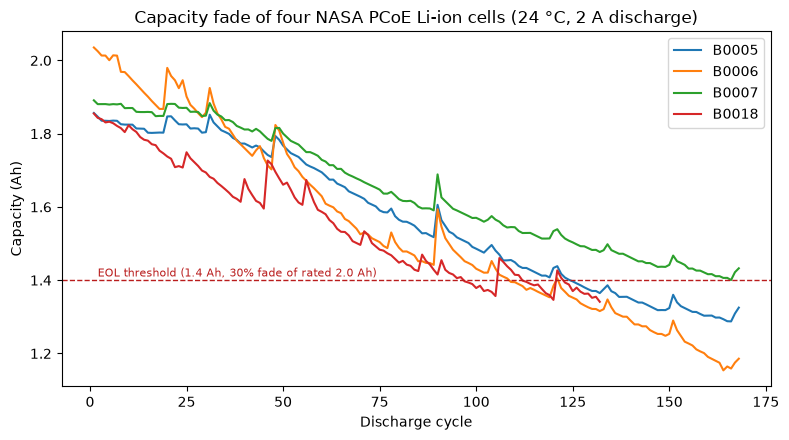

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
for cell, g in cap.groupby("cell"):
    ax.plot(g["cycle"], g["capacity_ah"], label=cell, linewidth=1.5)

ax.axhline(1.4, color="#B91C1C", linestyle="--", linewidth=1)
ax.text(2, 1.41, "EOL threshold (1.4 Ah, 30% fade of rated 2.0 Ah)", color="#B91C1C", fontsize=8)
ax.set_xlabel("Discharge cycle")
ax.set_ylabel("Capacity (Ah)")
ax.set_title("Capacity fade of four NASA PCoE Li-ion cells (24 °C, 2 A discharge)")
ax.legend()
fig.tight_layout()
fig.savefig("../figures/05_nasa_capacity_fade.png", dpi=150)
plt.show()

In [6]:
cap.to_csv("../data/processed/nasa_capacity.csv", index=False)

In [9]:
import numpy as np

N = 30

def relative(cell):
    g = cap[cap["cell"] == cell].set_index("cycle")["capacity_ah"]
    return g / g.iloc[:5].mean()

def first_below(cycles, values, thr=1.4):
    hit = cycles[values <= thr]
    return int(hit[0]) if len(hit) else np.nan

rows = []
curves = {}
for target in CELLS:
    g = cap[cap["cell"] == target]
    t = g["cycle"].to_numpy()
    y = g["capacity_ah"].to_numpy()
    seen, future = t <= N, t > N

    slope, intercept = np.polyfit(t[seen], y[seen], 1)
    pred_lin = intercept + slope * t

    template = pd.concat([relative(c) for c in CELLS if c != target], axis=1).mean(axis=1)
    anchor = y[(t > N - 5) & seen].mean() / template.loc[N - 4:N].mean()
    pred_tpl = anchor * template.reindex(t).to_numpy()

    curves[target] = (t, y, pred_lin, pred_tpl)

    for name, pred in [("Linear (own first 30)", pred_lin), ("Fleet template", pred_tpl)]:
        rows.append({
            "cell": target,
            "method": name,
            "rmse_ah": np.sqrt(np.mean((pred[future] - y[future]) ** 2)),
            "eol_true": first_below(t, y),
            "eol_pred": first_below(t, pred),
        })

res = pd.DataFrame(rows)
res["eol_error"] = res["eol_pred"] - res["eol_true"]
print(res.round(3))
print(res.groupby("method")["rmse_ah"].mean().round(4))
print(list(curves.keys()))

    cell                 method  rmse_ah  eol_true  eol_pred  eol_error
0  B0005  Linear (own first 30)    0.263     125.0       NaN        NaN
1  B0005         Fleet template    0.029     125.0     128.0        3.0
2  B0006  Linear (own first 30)    0.056     109.0     114.0        5.0
3  B0006         Fleet template    0.133     109.0     164.0       55.0
4  B0007  Linear (own first 30)    0.225       NaN       NaN        NaN
5  B0007         Fleet template    0.086       NaN     130.0        NaN
6  B0018  Linear (own first 30)    0.112      97.0      83.0      -14.0
7  B0018         Fleet template    0.042      97.0      99.0        2.0
method
Fleet template           0.0723
Linear (own first 30)    0.1639
Name: rmse_ah, dtype: float64
['B0005', 'B0006', 'B0007', 'B0018']


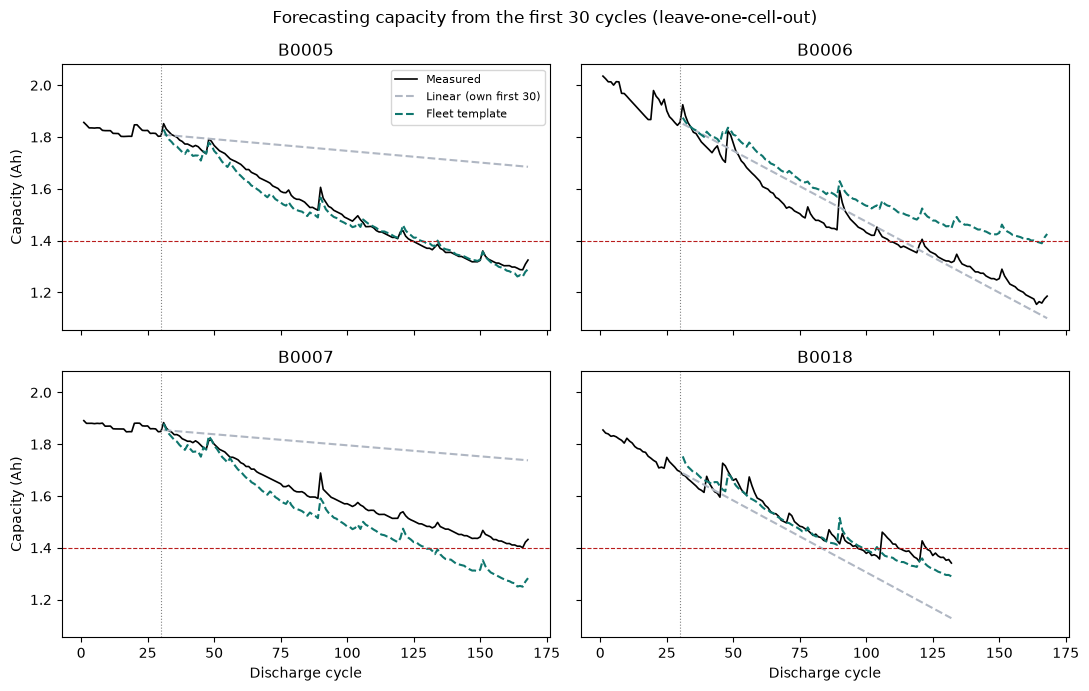

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (cell, (t, y, p_lin, p_tpl)) in zip(axes.flat, curves.items()):
    ax.plot(t, y, color="black", linewidth=1.2, label="Measured")
    ax.plot(t[t > N], p_lin[t > N], "--", color="#B0B7C3", label="Linear (own first 30)")
    ax.plot(t[t > N], p_tpl[t > N], "--", color="#0F766E", label="Fleet template")
    ax.axvline(N, color="grey", linewidth=0.8, linestyle=":")
    ax.axhline(1.4, color="#B91C1C", linewidth=0.8, linestyle="--")
    ax.set_title(cell)

axes[0, 0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Discharge cycle")
for ax in axes[:, 0]:
    ax.set_ylabel("Capacity (Ah)")
fig.suptitle("Forecasting capacity from the first 30 cycles (leave-one-cell-out)")
fig.tight_layout()
fig.savefig("../figures/06_nasa_forecast.png", dpi=150)
plt.show()

In [11]:
def evaluate(N):
    out = []
    for target in CELLS:
        g = cap[cap["cell"] == target]
        t = g["cycle"].to_numpy()
        y = g["capacity_ah"].to_numpy()
        seen, future = t <= N, t > N

        slope, intercept = np.polyfit(t[seen], y[seen], 1)
        pred_lin = intercept + slope * t

        template = pd.concat([relative(c) for c in CELLS if c != target], axis=1).mean(axis=1)
        anchor = y[(t > N - 5) & seen].mean() / template.loc[N - 4:N].mean()
        pred_tpl = anchor * template.reindex(t).to_numpy()

        for name, pred in [("Linear", pred_lin), ("Template", pred_tpl)]:
            out.append({"N": N, "cell": target, "method": name,
                        "rmse_ah": np.sqrt(np.mean((pred[future] - y[future]) ** 2))})
    return pd.DataFrame(out)

sens = pd.concat([evaluate(n) for n in [30, 60, 80]])
print(sens.pivot_table(index="cell", columns=["N", "method"], values="rmse_ah").round(3))
print(sens.groupby(["N", "method"])["rmse_ah"].mean().round(4))
sens.to_csv("../data/processed/nasa_sensitivity.csv", index=False)

N          30              60              80         
method Linear Template Linear Template Linear Template
cell                                                  
B0005   0.263    0.029  0.174    0.026  0.061    0.040
B0006   0.056    0.133  0.093    0.067  0.181    0.059
B0007   0.225    0.086  0.104    0.077  0.024    0.052
B0018   0.112    0.042  0.043    0.038  0.069    0.045
N   method  
30  Linear      0.1639
    Template    0.0723
60  Linear      0.1036
    Template    0.0522
80  Linear      0.0840
    Template    0.0489
Name: rmse_ah, dtype: float64


In [12]:
res.to_csv("../data/processed/nasa_forecast_results.csv", index=False)